# IMA207 - Practical work on SAR statistics

### Emanuele DALSASSO, Florence TUPIN, Cristiano ULONDU MENDES, Thomas BULTINGAIRE

### Statistics and despeckling

The practical work is divided in 3 parts

- A. empirical checking of the distributions seen in course for synthetic speckle
- B. computation of equivalent number of looks using images of physically homogeneous areas
- C. spatial multi-looking and implementation of the Lee filter

You have at your disposal several images of various areas acquired by different acquisition modes.
- An oceanfront in São-Paulo acquired by Sentinel-1 sensor (ESA) in GRD (Ground Range Detected) mode
- A farmland near from Bologne (Italy) acquired by TerraSAR-X sensor (ESA) in MGD (Multi Look Ground Range Detected) mode
- An area near from Rome acquired by TerraSAR-X sensor (ESA) in SLC (Single Look Complex) mode
- A temporal stack of images acquired at Flevoland in Netherlands by Alos sensor (JAXA) in SLC mode

Some useful functions are available in the file *mvalab.py*.

### Name: **APPERT Maxime**

#### Instructions

To solve this practical session, answer the questions below. Then export the notebook with the answers using the menu option **File -> Download as -> Notebook (.ipynb)**. Then [submit the resulting file on e-campus by next week.

### Import the libraries and packages we are going to use
The following cell imports all that is going to be necessary for the practical work

In [ ]:
!wget https://perso.telecom-paristech.fr/tupin/TPSAR/mvalab.py

--2024-06-09 22:06:37--  https://perso.telecom-paristech.fr/tupin/TPSAR/mvalab.py
Resolving perso.telecom-paristech.fr (perso.telecom-paristech.fr)... 137.194.22.227, 2a04:8ec0:0:a::89c2:16e3
Connecting to perso.telecom-paristech.fr (perso.telecom-paristech.fr)|137.194.22.227|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 68071 (66K) [text/x-python]
Saving to: ‘mvalab.py’

mvalab.py           100%[===================>]  66.48K  --.-KB/s    in 0.1s    

2024-06-09 22:06:39 (477 KB/s) - ‘mvalab.py’ saved [68071/68071]



In [ ]:
import scipy
from scipy import signal
import scipy.signal
import scipy as spy
import scipy.fftpack
from scipy import ndimage
from scipy import special
from scipy import ndimage
import numpy as np
import math
import matplotlib.pyplot as plt
import mvalab as mvalab
from urllib.request import urlopen
import cmath

plt.rcParams['figure.figsize'] = [15, 15]
plt.rcParams['figure.max_open_warning'] = 30

## A. Single look data distributions

In this part, we will simulate an SLC (Single Look Complex) SAR image representing an homogeneous area and analyze the pdfs of its intensity and phase.

#### Single look data simulation

According to the Goodman model, the real and imaginary parts of each pixel of an SLC SAR image are independent and identically distributed according to a Gaussian distribution centered and of variance equal to the reflectivity of the pixel divided by 2.\
Choose randomly a reflectity value $R$ in the interval $[100, 200]$ and create a SLC SAR image of size $150\times 150$ representing an homogeneous area of reflectivity $R$.

Affichage d'une image reelle
plt.show dans visusar : image 150 x 150


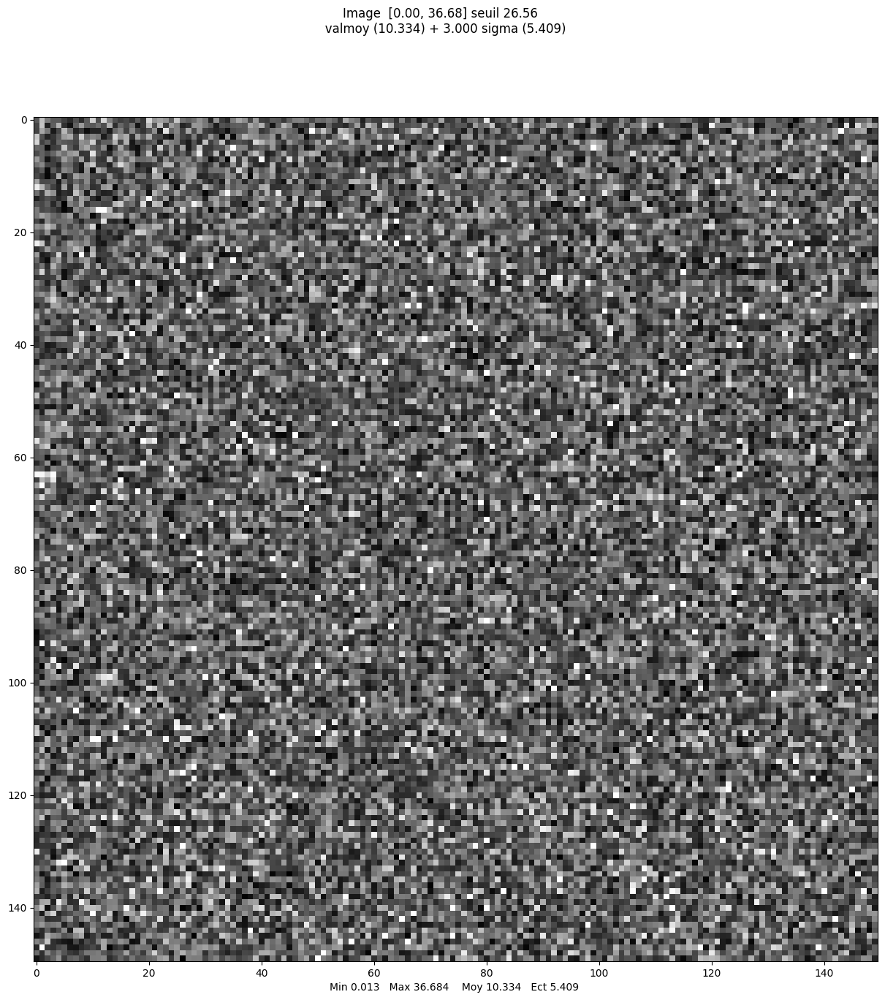

array([[ 9.33340174, 19.96210355, 12.86369918, ..., 10.68364367,
        14.25766784,  4.43617689],
       [ 7.20759083, 20.56536111,  3.47467713, ..., 14.40531469,
        18.43658756, 14.95785562],
       [ 7.05094507, 17.39318549, 12.49132267, ..., 17.51758496,
         2.80323721,  6.69114989],
       ...,
       [ 4.27488201, 26.27543068,  5.80042166, ...,  4.05461399,
         5.47247748, 10.08734353],
       [11.11430148,  4.98653936, 13.91387172, ...,  1.92561894,
        11.53616729, 10.24717853],
       [ 2.13108979,  4.83873831,  7.69067961, ..., 14.91298025,
        14.41377481,  3.93385728]])

In [ ]:
# Chose the reflectivity of the homogeneous area
R = np.random.uniform(100, 200) #complete

# Simulate the corresponding SLC image
ima_slc_real = np.random.normal(0, np.sqrt(R / 2), (150, 150))
ima_slc_imag = np.random.normal(0, np.sqrt(R / 2), (150, 150))
ima_slc = ima_slc_real + 1j * ima_slc_imag
mvalab.visusar(np.abs(ima_slc))

#### Data distributions for an homogeneous area

compute the distribution of the phase and intensity of your image.
Then, estimate the coefficient of variation:  
$\gamma=\frac{\sigma}{\mu}$ using intensity data (square of the modulus of the complex field)

In [ ]:
# Compute the intensity and the phase
ima_int = np.abs(ima_slc)**2 #complete
ima_ph = np.angle(ima_slc) #complete

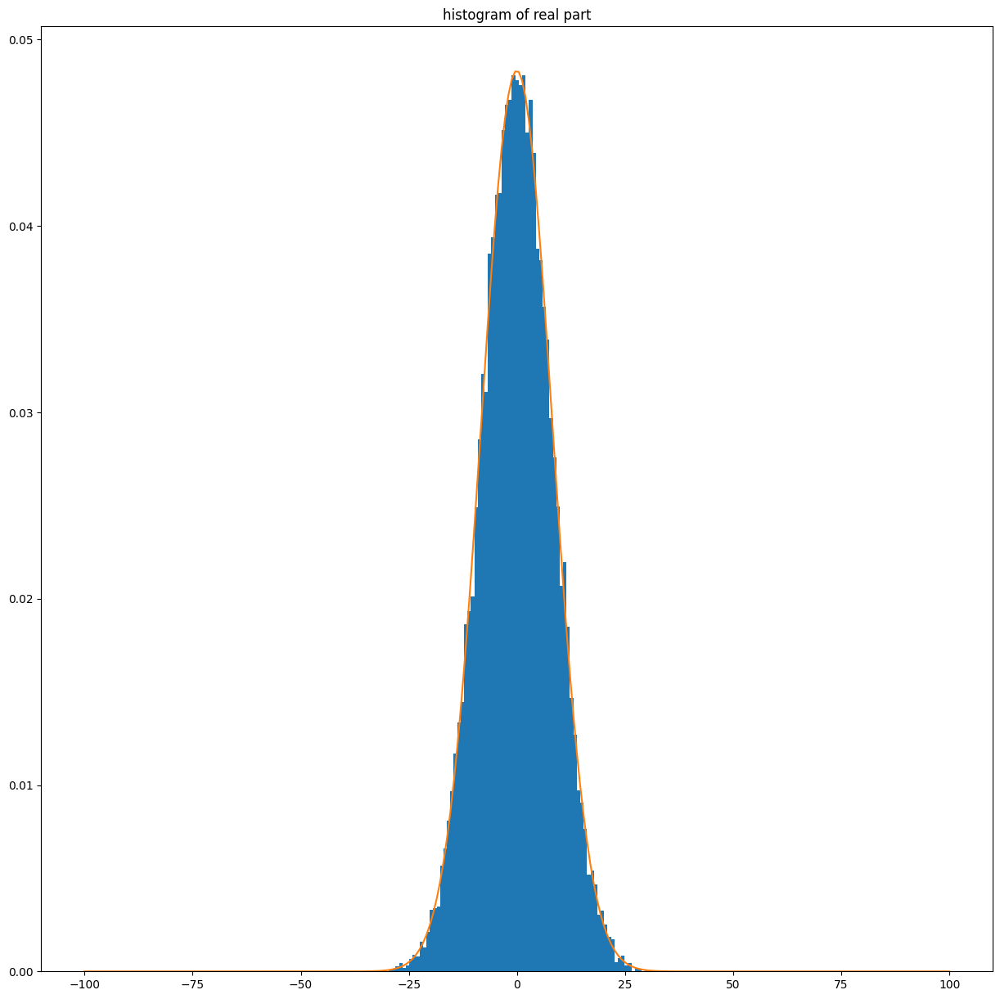

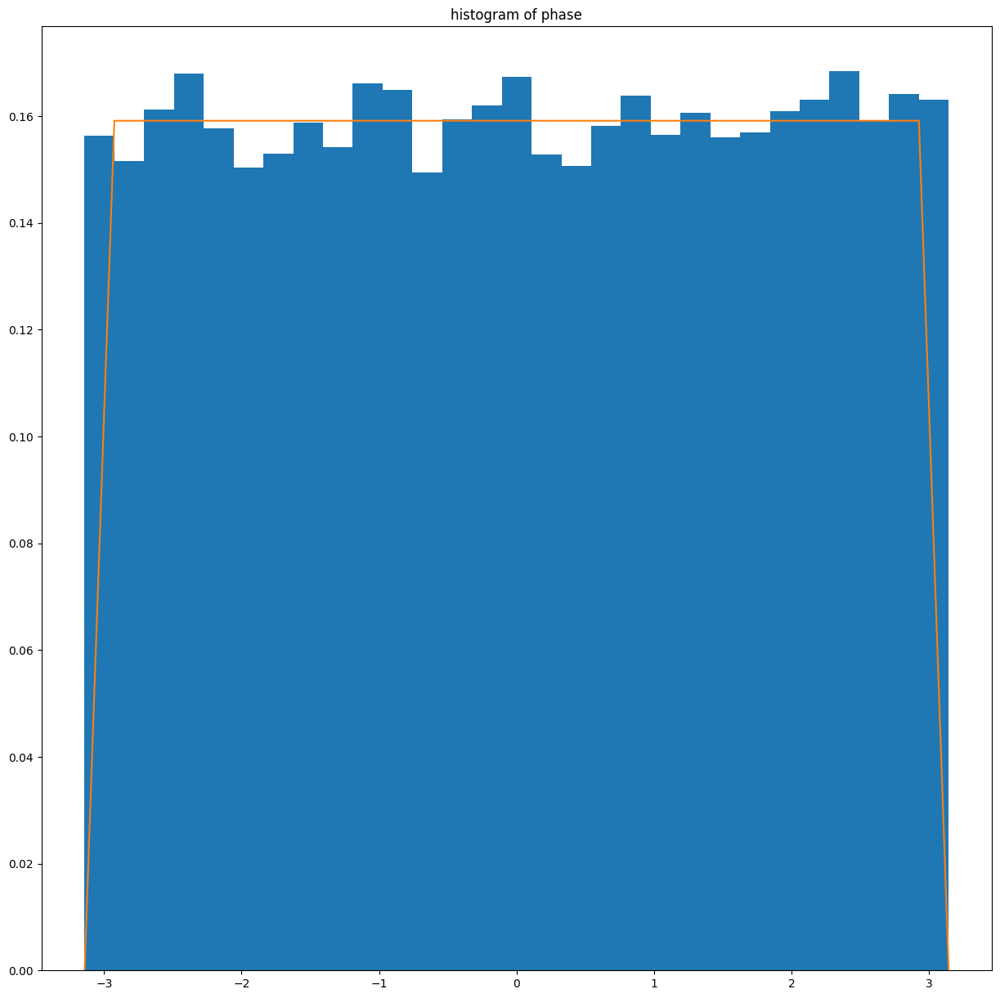

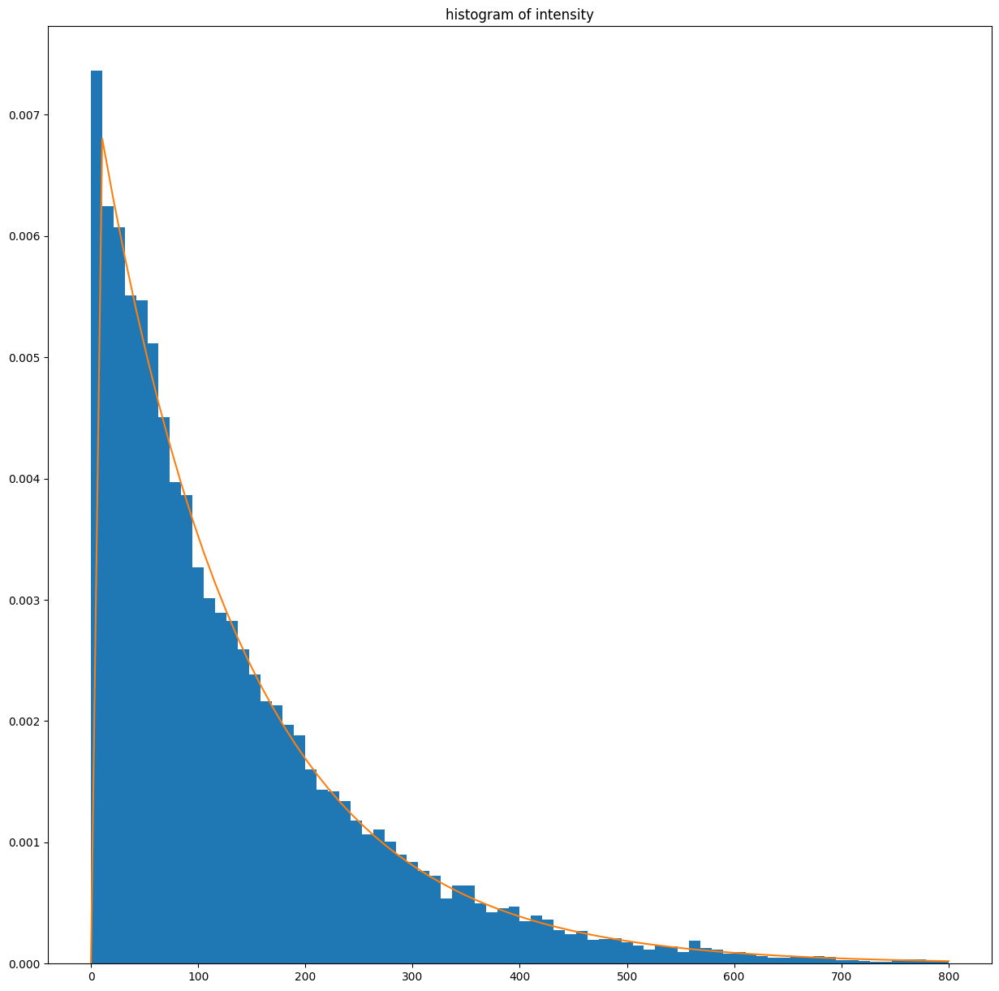

In [ ]:
# Plot the histograms and verify they match the theoretical distribution
# Use the right range of values to plot the histogram
# Choose the right distribution to do the fitting

# fitting of the distributions
# use the following ones :
# Gaussian pdf : scipy.stats.uniform
# Rayleigh pdf : scipy.stats.rayleigh
# Exponential pdf : scipy.stats.expon

#example for real part of the data
plt.figure()
_, bins, _ = plt.hist(np.real(ima_slc).ravel(),bins='auto',density=True,range=[-100,100])  # Gaussian distribution
mu, sigma = scipy.stats.norm.fit(np.real(ima_slc))
best_fit_line = scipy.stats.norm.pdf(bins, mu, sigma)
plt.plot(bins, best_fit_line)
plt.title('histogram of real part')
plt.show()


#complete for phase data: Uniform distribution
plt.figure()
_, bins, _ = plt.hist(ima_ph.ravel(), bins='auto', density=True, range=[-np.pi, np.pi])  # Uniform distribution
mu, sigma = scipy.stats.uniform.fit(np.real(ima_ph))
best_fit_line = scipy.stats.uniform.pdf(bins, mu, sigma)
plt.plot(bins, best_fit_line)
plt.title('histogram of phase')
plt.show()


#complete for intensity data: Exponential (Gamma) distribution
plt.figure()
_, bins, _ = plt.hist(ima_int.ravel(), bins='auto', density=True, range=[0, 800])  # Exponential distribution
mu, sigma = scipy.stats.expon.fit(np.real(ima_int))
best_fit_line = scipy.stats.expon.pdf(bins, mu, sigma)
plt.plot(bins, best_fit_line)
plt.title('histogram of intensity')
plt.show()

In [ ]:
# Compute the coefficient of variation on the homogeneous area in intensity

m_I = np.mean(ima_int) #complete
sigma_I = np.std(ima_int) #complete
coeff_var_I = sigma_I/m_I
print(coeff_var_I)

0.9969148585533049


### Question A.1.

Did you find the distributions seen in the course ? (recapitulate them).
Did you find the correct value for the coefficient of variation ? Could this coefficient be less than the theoretical value ?

### Answer A.1.
We did find the distributions seen in the course, however the coefficient of variation we found is slightly less that the theoretical value (>0.01). This is because we use a random value and experiment upon it, however, this allows for lsight variations in the experimental result.

## B. Computation of the Equivalent Number of looks on homogeneous areas
In this part you have at your disposal 2 images of a part a ocean (São-Paulo) and a part of a field (Bologne, Italy). The first is acquired by Sentinel-1 GRD, and the second by TerraSAR-X GRD. The multi-looking has been done by the data provider (ESA, European Space Agency).

Use the value of the coefficient of variation to find the Equivalent Number of Looks (ENL) of the Sentinel-1 GRD and TerraSAR-X GRD data.
The formula is :
- $\gamma_I=\frac{1}{\sqrt{L}}$ for intensity data

In [ ]:
# Download the images
!wget "https://partage.imt.fr/index.php/s/M3yeW5ozcsHyigR/download/s1_grd_saopaulo.npy"
!wget "https://partage.imt.fr/index.php/s/TTRfS6XKCzSM6cS/download/tsx_grd_bologne.npy"

--2024-06-09 22:06:49--  https://partage.imt.fr/index.php/s/M3yeW5ozcsHyigR/download/s1_grd_saopaulo.npy
Resolving partage.imt.fr (partage.imt.fr)... 193.48.235.12
Connecting to partage.imt.fr (partage.imt.fr)|193.48.235.12|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2097280 (2.0M) [application/octet-stream]
Saving to: ‘s1_grd_saopaulo.npy’

s1_grd_saopaulo.npy 100%[===================>]   2.00M   434KB/s    in 4.7s    

2024-06-09 22:06:55 (434 KB/s) - ‘s1_grd_saopaulo.npy’ saved [2097280/2097280]

--2024-06-09 22:06:55--  https://partage.imt.fr/index.php/s/TTRfS6XKCzSM6cS/download/tsx_grd_bologne.npy
Resolving partage.imt.fr (partage.imt.fr)... 193.48.235.12
Connecting to partage.imt.fr (partage.imt.fr)|193.48.235.12|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2097280 (2.0M) [application/octet-stream]
Saving to: ‘tsx_grd_bologne.npy’

tsx_grd_bologne.npy 100%[===================>]   2.00M   432KB/s    in 4.7s    

2024-06-09

Affichage d'une image reelle
plt.show dans visusar : image 250 x 250


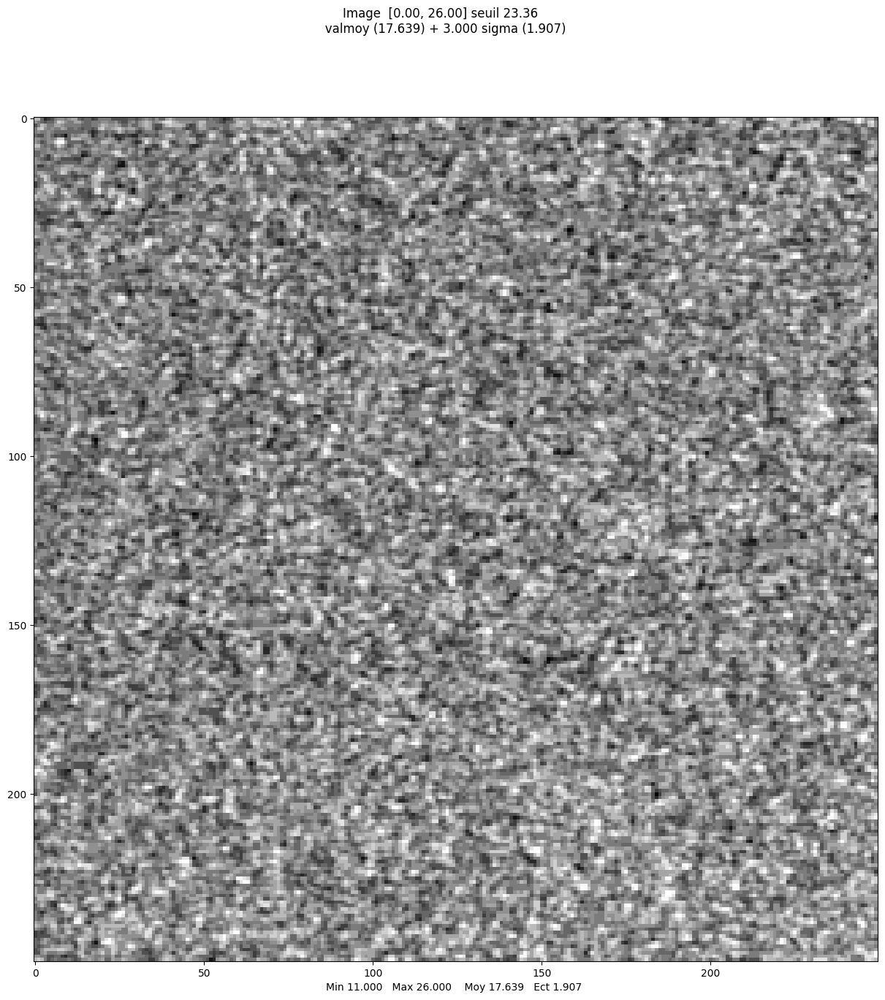

--- coeff var and L ---
0.11752811
72.39631984996059


In [ ]:
im_s1grd = np.load("s1_grd_saopaulo.npy").astype(np.float32) #amplitude
im_s1grd_mer = im_s1grd[50:300, 100:350]
mvalab.visusar(im_s1grd_mer)

# compute coefficient of variation and number of looks
coeff_var_grd = np.std(np.abs(im_s1grd_mer[0])) / np.mean(np.abs(im_s1grd_mer[0]))
L_grd = 1 / (coeff_var_grd**2) #complete
print('--- coeff var and L ---')
print(coeff_var_grd)
print(L_grd)

Affichage d'une image reelle
plt.show dans visusar : image 250 x 250


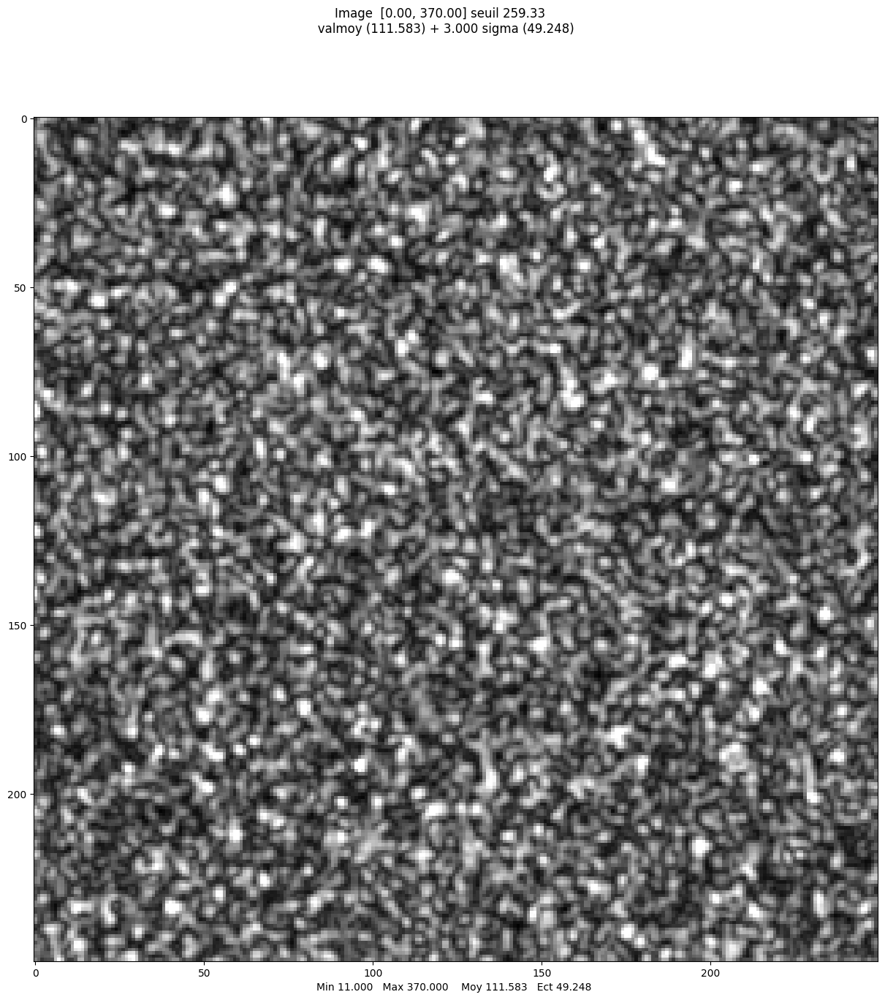

--- coeff var and L ---
0.43491048
5.286889844051529


In [ ]:
im_tsxgrd = np.load("tsx_grd_bologne.npy").astype(np.float32) #amplitude
im_tsxgrd_champ = im_tsxgrd[700:950, 300:550]
mvalab.visusar(im_tsxgrd_champ)

# compute coefficient of variation and number of looks
coeff_var_grd2 = np.std(np.abs(im_tsxgrd_champ[0])) / np.mean(np.abs(im_tsxgrd_champ[0]))
L_grd2 = 1 / (coeff_var_grd2**2) #complete
print('--- coeff var and L ---')
print(coeff_var_grd2)
print(L_grd2)

### Question B.1
Comment the number of looks you have found for GRD date from Sentinel-1 and TerraSAR-X (is it an integer value ? why not ? what does it mean ?).

### Answer B.1

We see we get significantly more looks in Sentinel-1 than in TerraSAR-X, I think this is because TerraSAR-X is more homogenous. We do no get an integer value, this is because our samples are not independent.

## C. Spatial multi-looking and implementation of the Lee filter

In this part we will try simple speckle reduction method using the following step :
- first we will compute a mean filter
- then we will compute the local coefficient of variation (using the same size for the moving window)
- finally we will combine these two results to obtain the Lee filter.

## C.1 Computation of the mean filter
Compute the mean filter using a 2D convolution.

In [ ]:
# Download the image
!wget "https://partage.imt.fr/index.php/s/cbRqjnSJEfD2zJ8/download/tsx_slc_rome.npy"

--2024-06-09 22:07:03--  https://partage.imt.fr/index.php/s/cbRqjnSJEfD2zJ8/download/tsx_slc_rome.npy
Resolving partage.imt.fr (partage.imt.fr)... 193.48.235.12
Connecting to partage.imt.fr (partage.imt.fr)|193.48.235.12|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8388736 (8.0M) [application/octet-stream]
Saving to: ‘tsx_slc_rome.npy’

tsx_slc_rome.npy    100%[===================>]   8.00M   451KB/s    in 19s     

2024-06-09 22:07:22 (442 KB/s) - ‘tsx_slc_rome.npy’ saved [8388736/8388736]



Affichage d'une image complexe : on prend le module
plt.show dans visusar : image 1024 x 1024


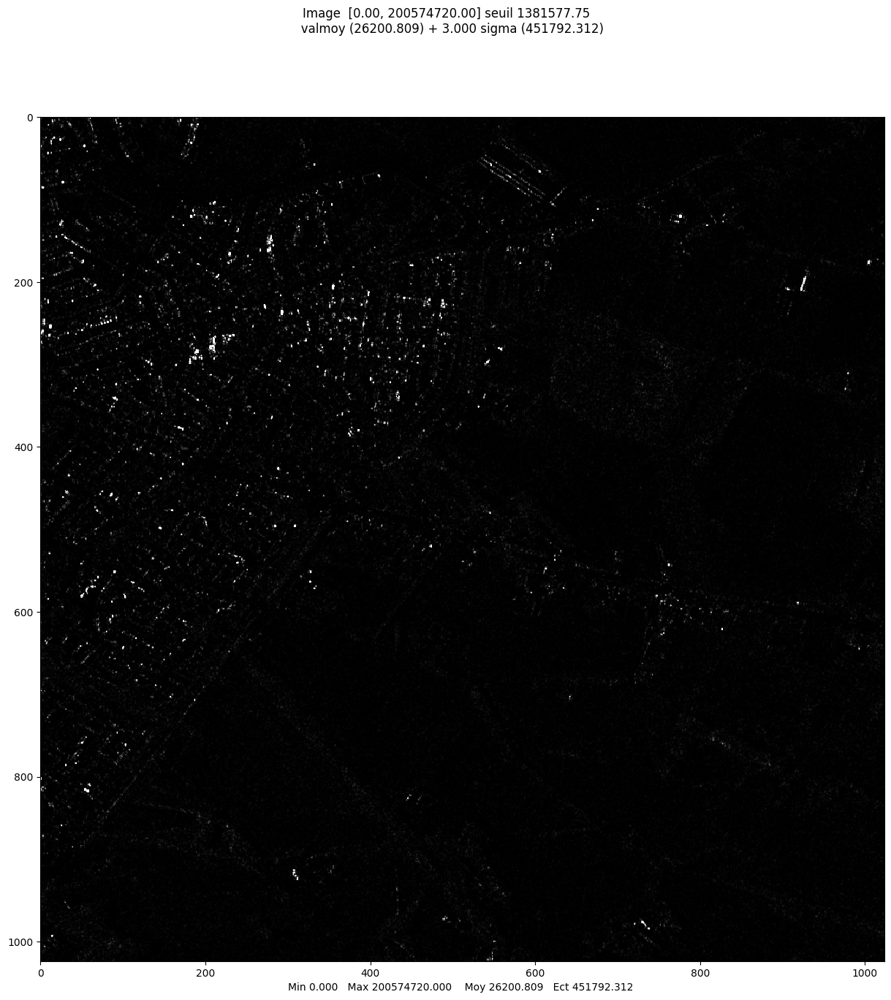

Affichage d'une image complexe : on prend le module
plt.show dans visusar : image 1024 x 1024


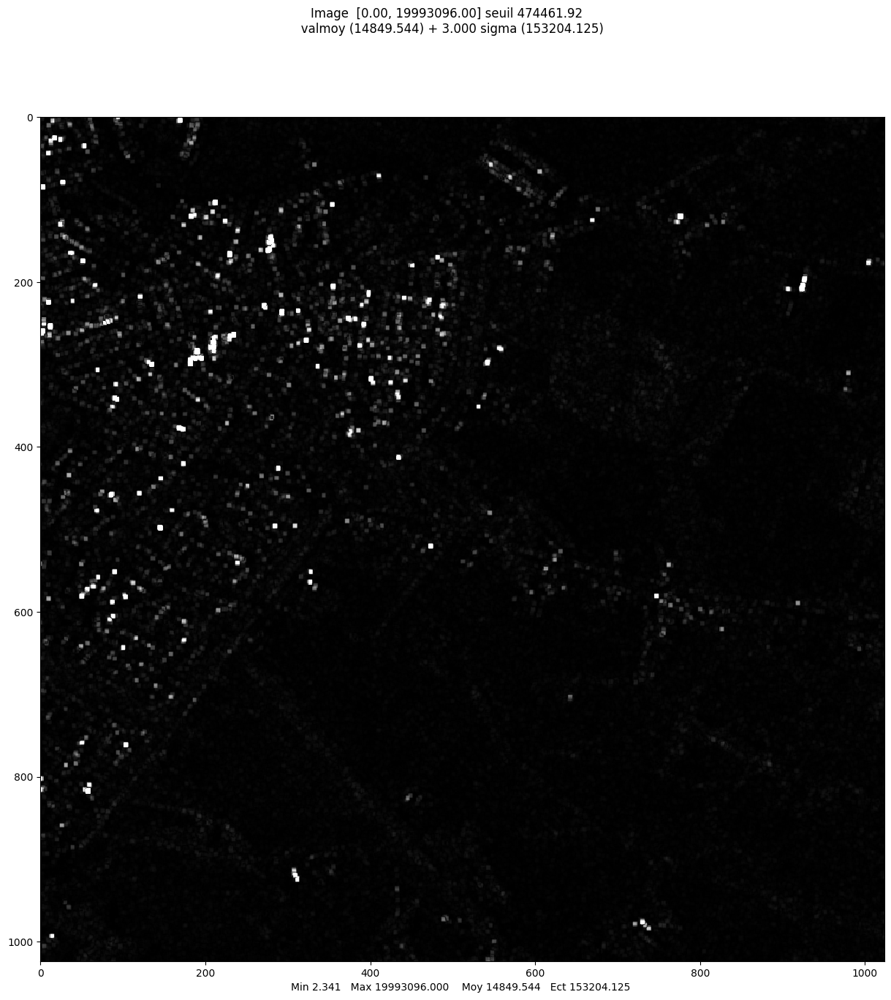

array([[98676.4453125 , 69889.4921875 , 70480.359375  , ...,
         5148.99414062,  3760.82739258,  4049.05761719],
       [83300.71875   , 59556.5546875 , 58841.62109375, ...,
         4712.06103516,  3502.07348633,  3505.28491211],
       [69831.9140625 , 46138.51171875, 47101.60546875, ...,
         2542.71948242,  1916.21191406,  1728.25463867],
       ...,
       [ 2371.38549805,  1129.71899414,   423.75323486, ...,
         5935.09667969,  7178.37451172,  9632.79785156],
       [ 2734.51416016,  1455.3458252 ,   496.16259766, ...,
         3034.30053711,  3425.06787109,  4264.50292969],
       [ 3730.74194336,  2453.85253906,   628.67218018, ...,
         1572.53295898,  3902.87866211,  3441.72680664]])

In [ ]:
ima_tsxslc = np.load("tsx_slc_rome.npy") #amplitude

# take the intensity
ima_int = ima_tsxslc**2 #complete
mvalab.visusar(ima_int)

# create the average window
size_window = 5
mask_loc = np.ones((size_window, size_window)) / (size_window**2) #complete

# compute the mean image (intensity data)
ima_int_mean = ndimage.convolve(ima_int, mask_loc, mode='reflect') #complete

# display the result
mvalab.visusar(ima_int_mean)

### Question C.1
What is the effect of the mean filter ? (advantages and drawbacks). What is the influence of the window size ?

### Answer C.1

A mean filter reduces noise and smoothes images. It works by averaging the pixel values in a window around each pixel and replacing the center pixel value with this average. It is useful for reducing noising and smoothing operations, however it can lose details that could be important or introduce strange artefacts.

The window size defines how far we go from each pixel to calculate the mean, the bigger the window size, the more homogeneous the image will be.

## C.2 Lee filter

Given a neighborhood, the Lee filter of an image $I_s$ can be computed by the following steps:

*   Compute the local mean of the image $\hat{\mu}_{s}$
*   Compute $k_s$ given by:
$$
  k_s=1- \frac{\gamma_{Sp}^2}{\hat{\gamma}_s^2}
$$
where $\gamma_{Sp}$ is the theoretical value of the coefficient of variation for a pure speckle ($\gamma_{Sp}=\frac{1}{\sqrt{L}}$ for a L-look intensity image), and $\hat{\gamma}_s$ is the empirical value of the coefficient of variation for the given neighborhood.
*   Compute the final filtered image
$$
  \hat{I}_s= \hat{\mu}_{s}+k_s (I_s-\hat{\mu}_{s})
$$

Create a function performing Lee filter on an image, for a given neighborhood and number $L$ of look.

Then, knowing that a SLC image is a 1-look image, compute the Lee filter on the intensity image of "ima_tsxslc"

Affichage d'une image complexe : on prend le module
plt.show dans visusar : image 1024 x 1024


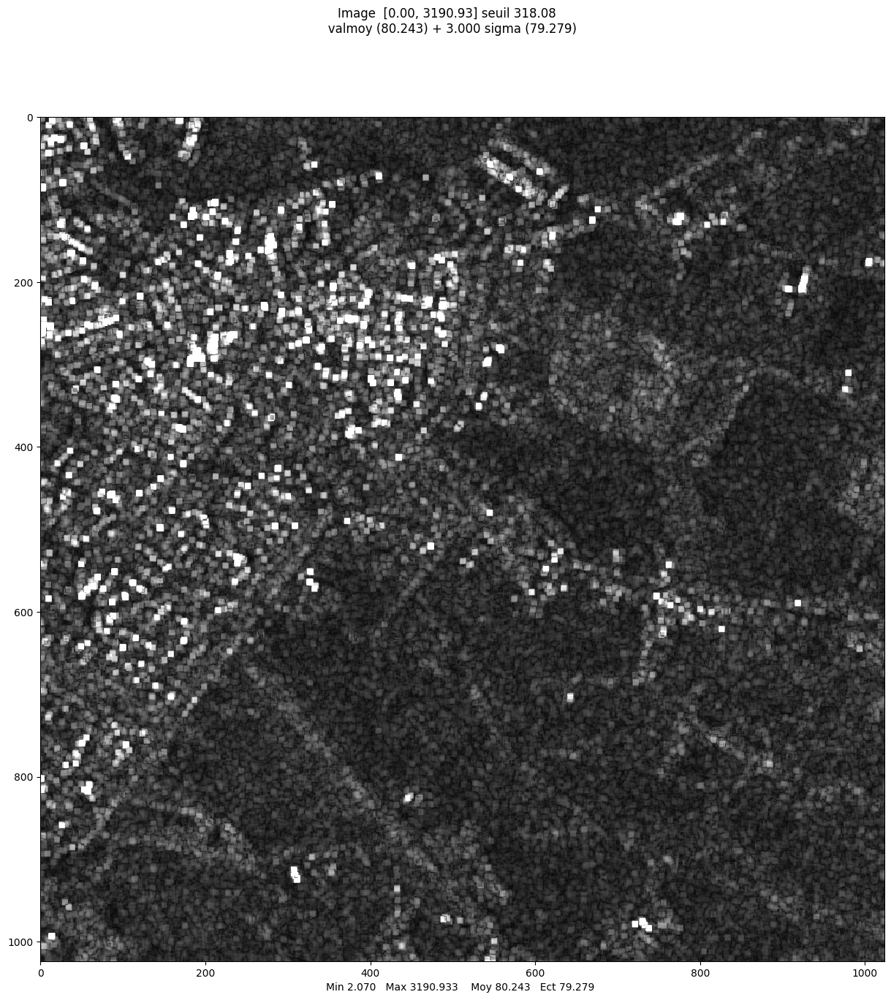

Affichage d'une image complexe : on prend le module
plt.show dans visusar : image 1024 x 1024


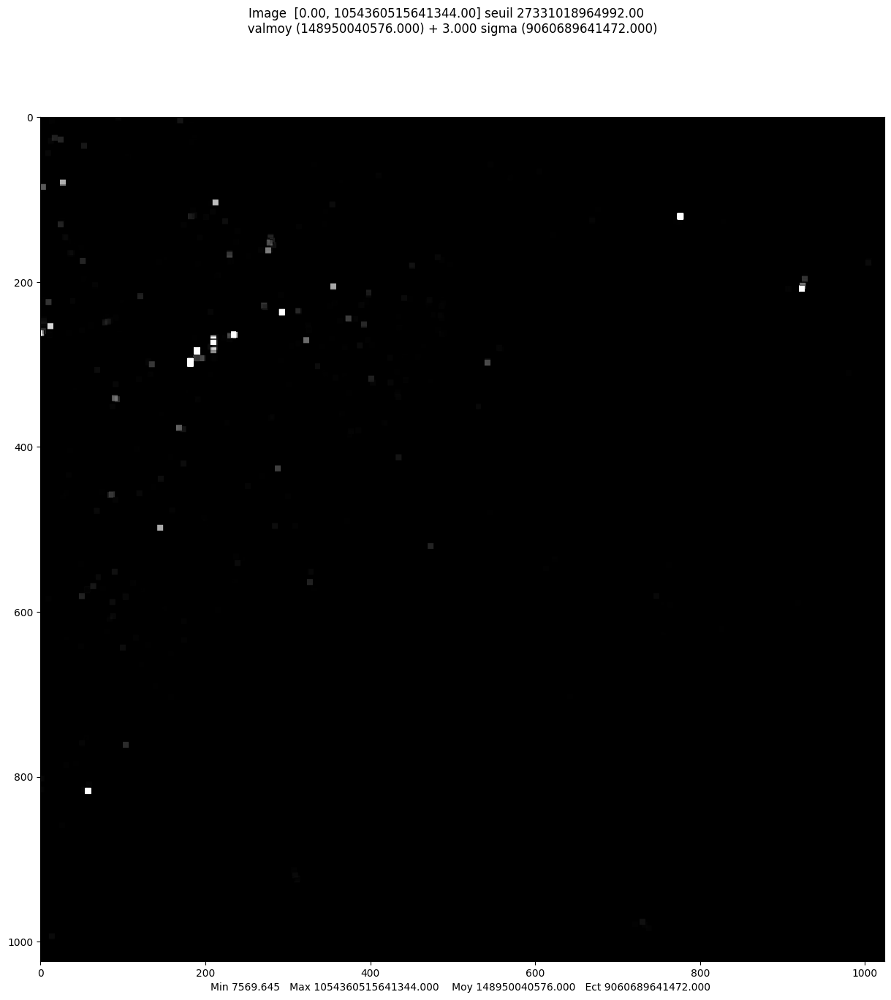

Affichage d'une image complexe : on prend le module
plt.show dans visusar : image 1024 x 1024


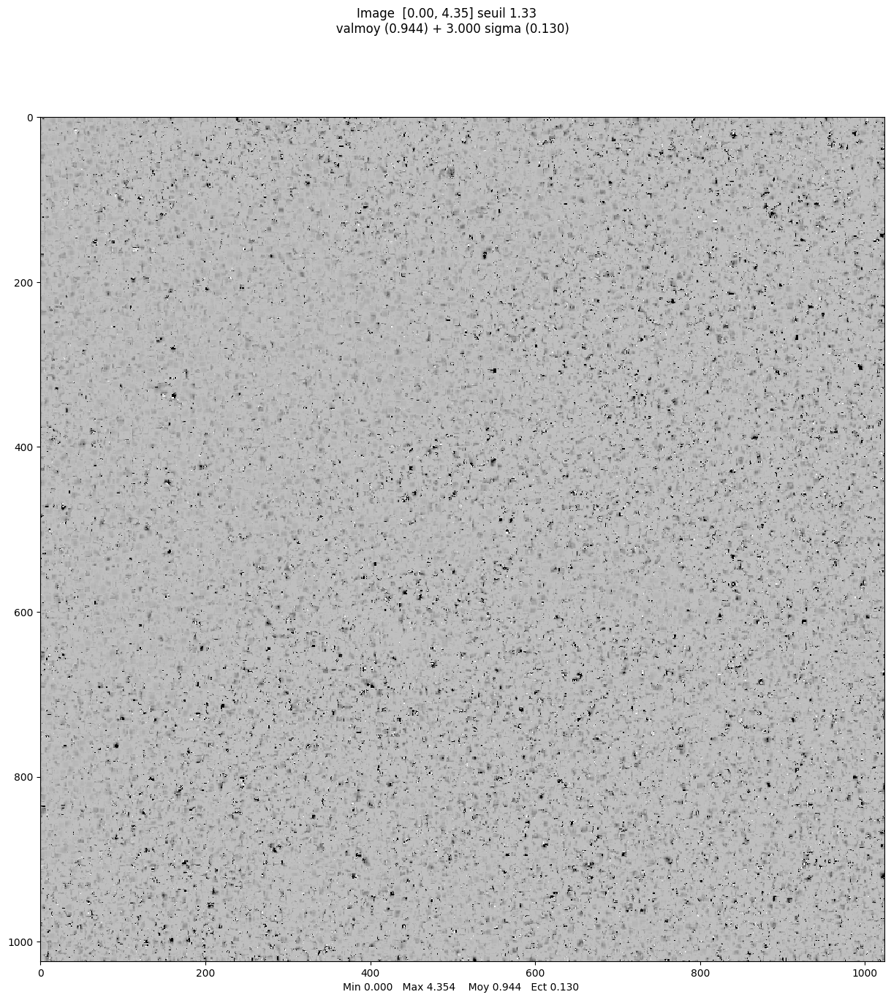

Affichage d'une image complexe : on prend le module
plt.show dans visusar : image 1024 x 1024


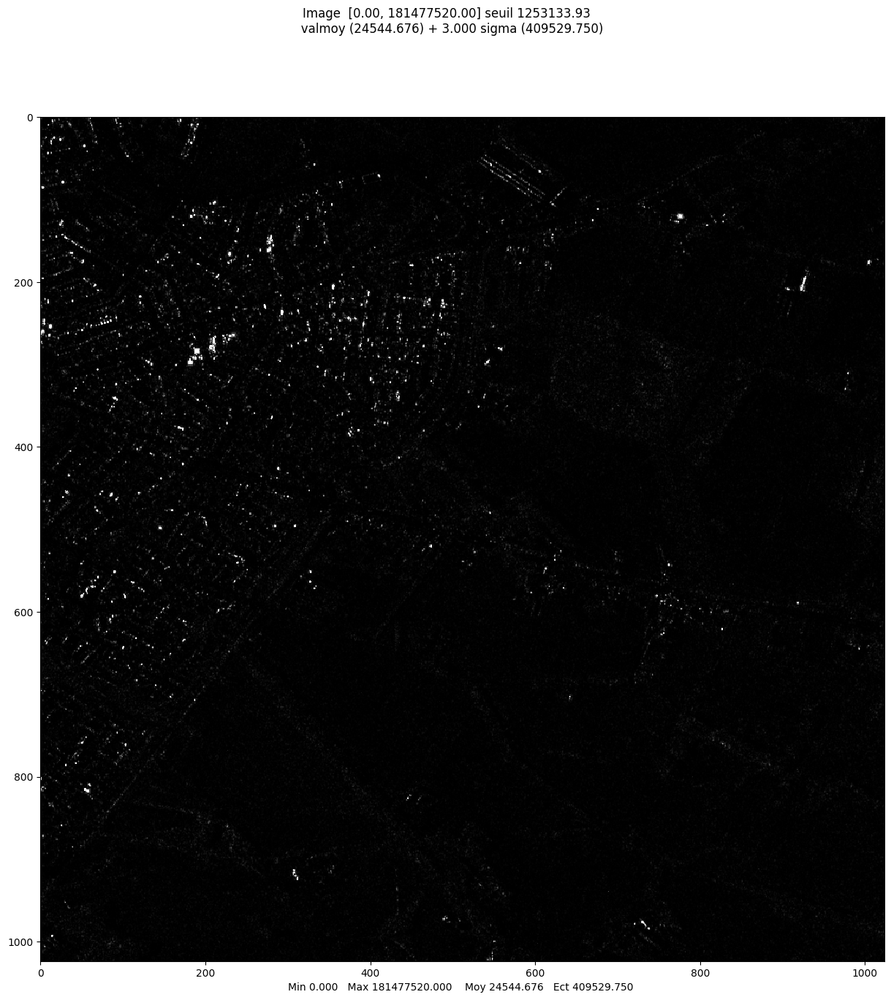

array([[158126.296875  , 140234.59375   , 219781.28125   , ...,
          4190.58349609,   8156.04345703,  14401.1875    ],
       [178126.125     , 205538.484375  , 195329.671875  , ...,
          2136.54125977,   4560.35498047,   1164.64697266],
       [ 59907.99609375, 332866.        , 155714.        , ...,
          2292.80395508,    760.29156494,    718.55462646],
       ...,
       [ 10909.        ,   8621.        ,   3960.99975586, ...,
         12880.34960938,   7126.84667969,   4424.06396484],
       [  8020.        ,  15112.        ,  10376.        , ...,
         11087.40722656,   2327.7878418 ,  13946.01367188],
       [  2993.        ,   3249.        ,  13460.        , ...,
         11025.        ,   1709.00012207,  15977.00097656]])

In [ ]:
def lee_filter(im, neighborhood=7, L=1, visualize=False):

  # Mask
  mask = mask = np.ones((neighborhood, neighborhood)) / (neighborhood**2) #complete

  # Compute local mean image
  im_mean = ndimage.convolve(im, mask, mode='reflect') #complete

  # Compute local coefficient of variation (thanks to local variance and local mean)
  im_var = ndimage.convolve(im**2, mask, mode='reflect') - im_mean**2 #complete
  gamma_sp = 1 / np.sqrt(L)
  ks = 1 - (gamma_sp**2 / (im_var / im_mean**2)) #complete
  ks = np.clip(ks, 0, 1)

  # Compute Lee filter
  filtered_im = im_mean + ks * (im - im_mean) #complete

  # Visualizations
  if visualize:
    mvalab.visusar(np.sqrt(im_mean))
    mvalab.visusar(im_var)
    mvalab.visusar(np.sqrt(ks))

  return filtered_im


lee_filtered_int = lee_filter(ima_int, neighborhood=7, L=1, visualize=True) #complete
mvalab.visusar(lee_filtered_int)

### Question C.2
Which information is enhanced in the image of the local standard deviation ? In the image of the local coefficient of variation ? Which one is the more useful ?

### Answer C.2

In the image of the local standard deviation we can see that only the areas which present a high positive variation compared to their surrondings are represented. The rest of the image is black and it is hard to distinguish anything else. In the local coefficient of variation, high values indicate regions where the local standard deviation is large relative to the mean image, and vice versa. I think the local coefficient of variation is more useful as it normalizes variation which gives us more information relative changes across different intensity levels.

### Question C.3

Compare the results of the mean filter and the Lee filter. Study the influence of the size of the window of the filters.


### Answer C.3

We can see that the Lee filter is much better, as the mean filter results in significant blurring and loss of detail, especially with larger windows. The Lee filter provides a balance between noise reduction and the conservation of details. Larger windows improve noise reduction while still retaining some edge information.

## Filtering of image "Lely" and comparison with a deep learning algorithm
In this part, we will repeat the process done above to denoise a crop of image "Lely" using the Lee filter. Then, we will compare it with the result of a deep learning algorithm called SAR2SAR (https://arxiv.org/abs/2006.15037).

## C.4 Denoised image: SAR2SAR
The Lee filter presents some limits. More recent approaches to suppress noise rely on sofisticated algorithms. You can plot the image of Lely denoised using a deep learning algorthm called SAR2SAR and compare visually the result with the image filtered using the Lee filter.
  

In [ ]:
# Download the image
!wget https://perso.telecom-paristech.fr/tupin/TPSAR/pilelely/multitemp/lely_tuple_multitemp.IMA
!wget https://perso.telecom-paristech.fr/tupin/TPSAR/pilelely/multitemp/lely_tuple_multitemp.dim

--2024-06-09 22:07:30--  https://perso.telecom-paristech.fr/tupin/TPSAR/pilelely/multitemp/lely_tuple_multitemp.IMA
Resolving perso.telecom-paristech.fr (perso.telecom-paristech.fr)... 137.194.22.227, 2a04:8ec0:0:a::89c2:16e3
Connecting to perso.telecom-paristech.fr (perso.telecom-paristech.fr)|137.194.22.227|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 52428800 (50M)
Saving to: ‘lely_tuple_multitemp.IMA’

lely_tuple_multitem 100%[===================>]  50.00M  16.2MB/s    in 3.1s    

2024-06-09 22:07:34 (16.2 MB/s) - ‘lely_tuple_multitemp.IMA’ saved [52428800/52428800]

--2024-06-09 22:07:34--  https://perso.telecom-paristech.fr/tupin/TPSAR/pilelely/multitemp/lely_tuple_multitemp.dim
Resolving perso.telecom-paristech.fr (perso.telecom-paristech.fr)... 137.194.22.227, 2a04:8ec0:0:a::89c2:16e3
Connecting to perso.telecom-paristech.fr (perso.telecom-paristech.fr)|137.194.22.227|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 29
Savi

imz2mat : version janvier 2018.  Fichier à ouvrir : lely_tuple_multitemp.IMA
Fichier .dim version longue (lecture 3eme parametre) 
Fichier .dim version longue (lecture 4eme parametre)
Dans ximaread : lecture du canal 0/25
image en .IMA
image en .IMA
Fichier .dim version longue (lecture 3eme parametre) 
Fichier .dim version longue (lecture 4eme parametre)
image en .ima  512   512   canaux: 25  verif :  1
512 512
-type CFLOAT
lecture de  lely_tuple_multitemp.IMA  en quelconque 512 512 25  offset  0 <f 4  complex 1 blocksize 2097152
Boucle de lecture entre 0 et 25   sur 25 canaux
Lecture du canal 1/25
Données complexes (standard). Nouvelle version de imz2mat  <f
Lecture du canal 2/25
Données complexes (standard). Nouvelle version de imz2mat  <f
Lecture du canal 3/25
Données complexes (standard). Nouvelle version de imz2mat  <f
Lecture du canal 4/25
Données complexes (standard). Nouvelle version de imz2mat  <f
Lecture du canal 5/25
Données complexes (standard). Nouvelle version de imz2mat 

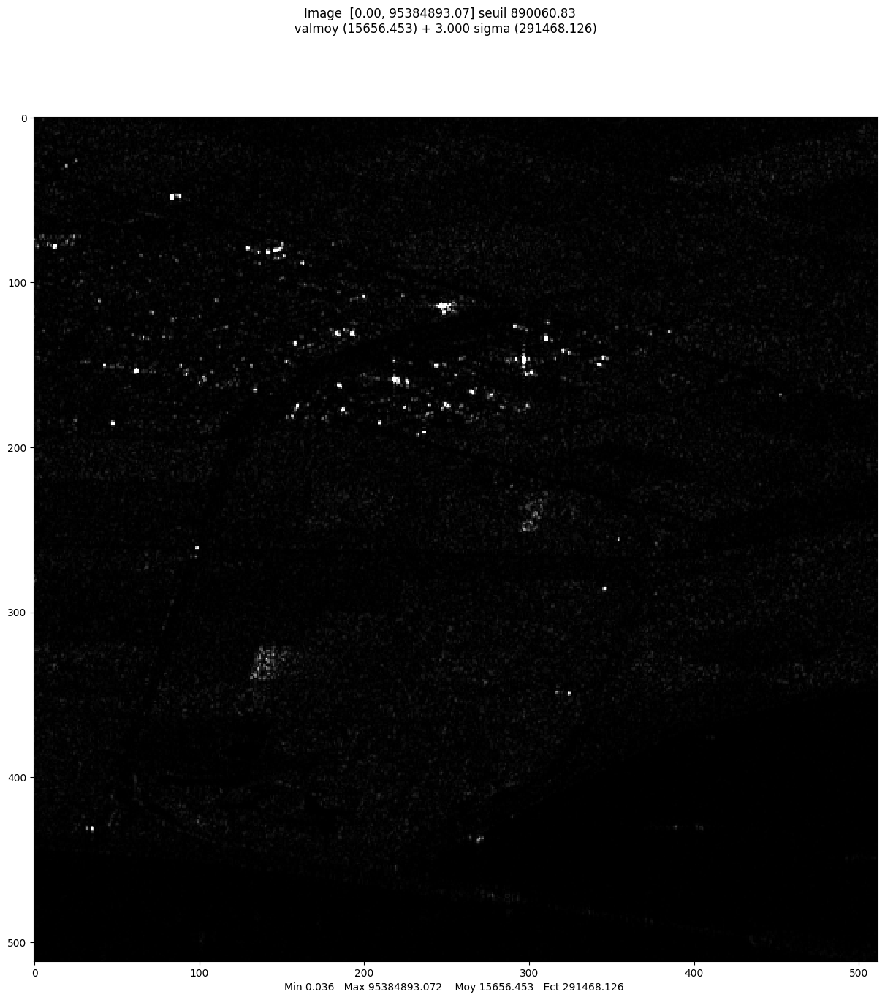

Affichage d'une image reelle
plt.show dans visusar : image 512 x 512


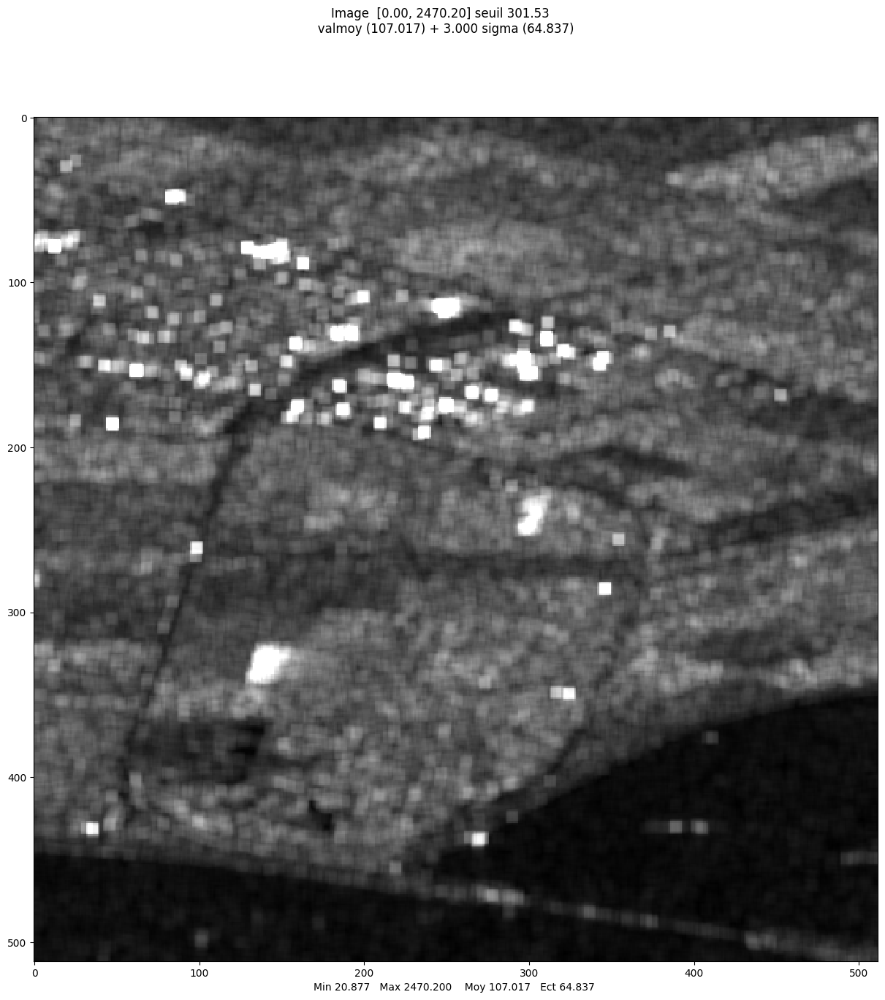

Affichage d'une image reelle
plt.show dans visusar : image 512 x 512


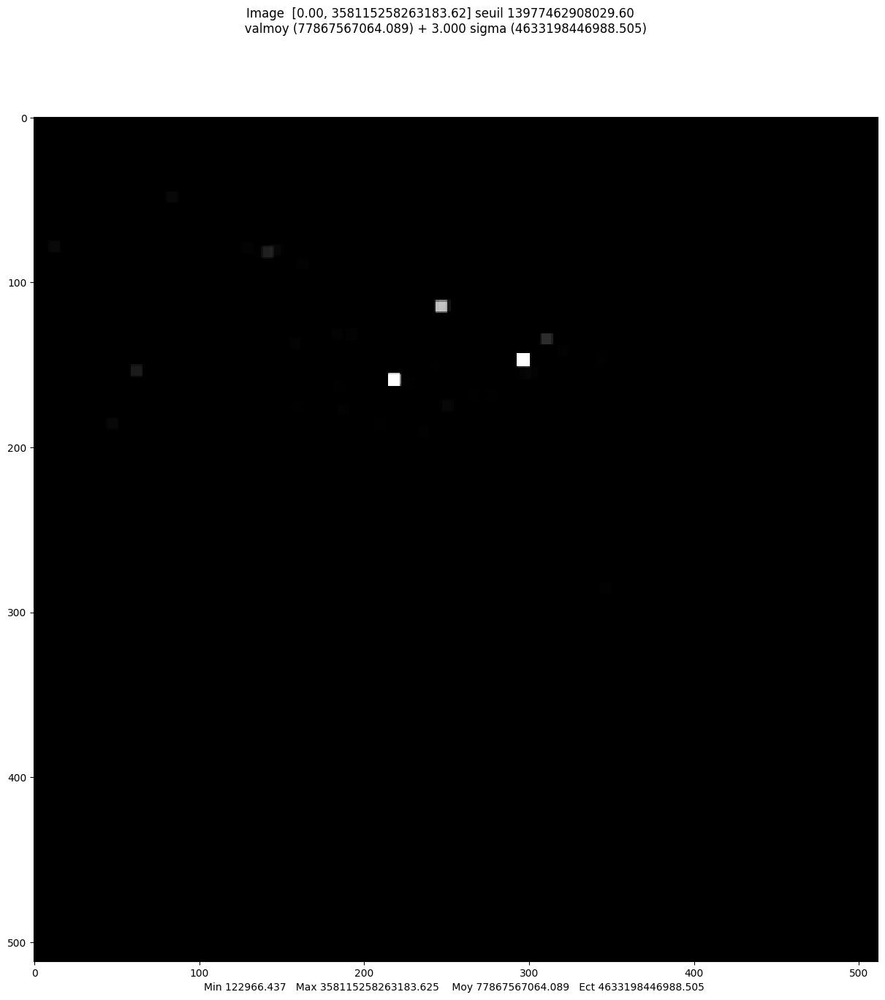

Affichage d'une image reelle
plt.show dans visusar : image 512 x 512


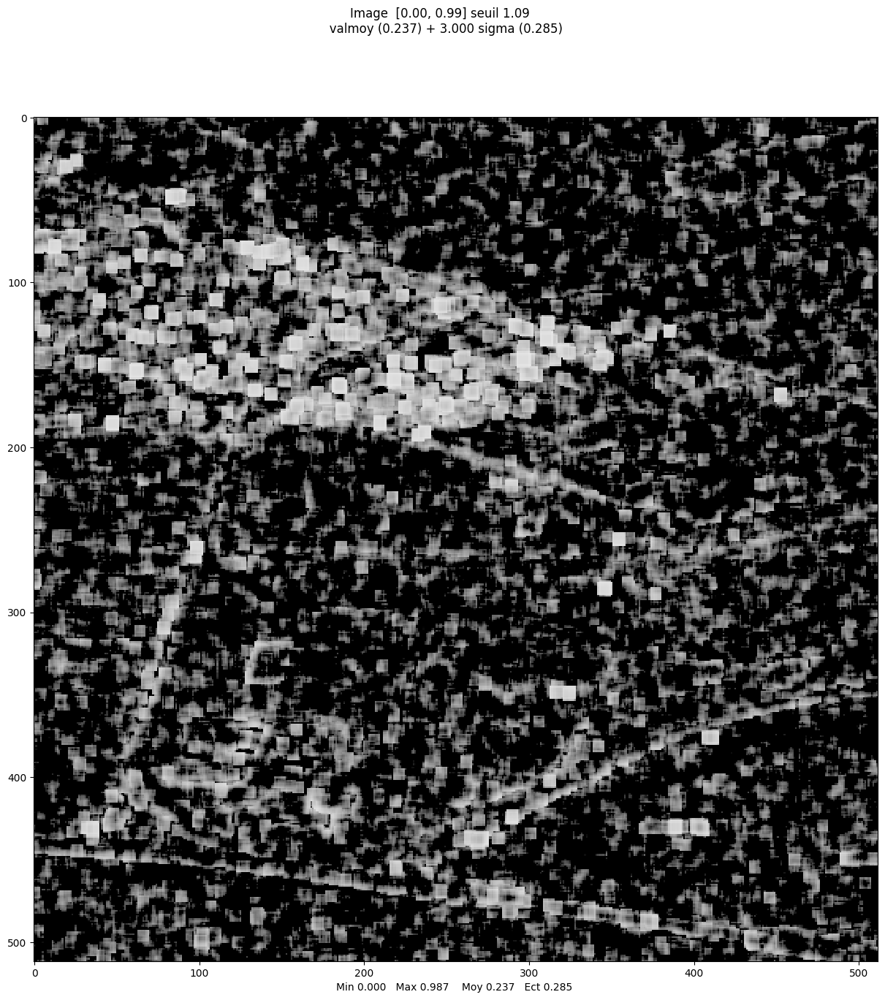

Affichage d'une image reelle
plt.show dans visusar : image 512 x 512


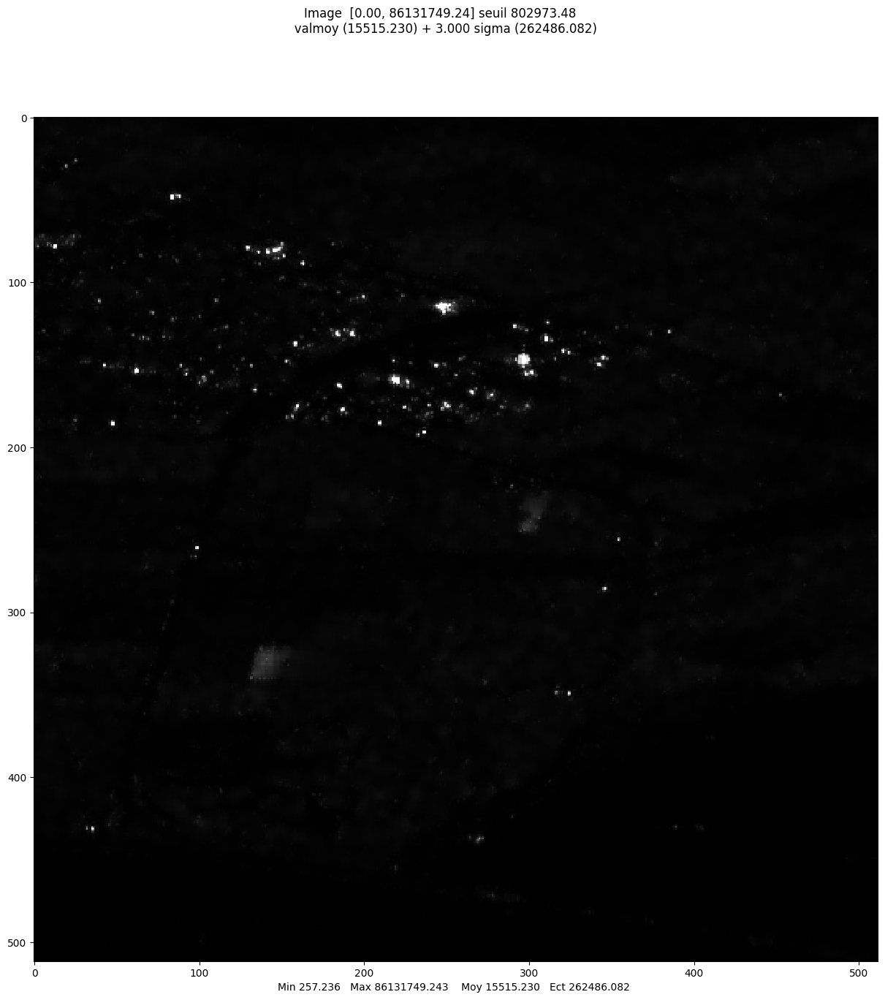

array([[ 6584.21020892,  7518.26399152, 10839.86159422, ...,
         7462.19176355,  6946.84237215,  8193.65293831],
       [ 5432.36189163,  8200.53536991,  7042.99784049, ...,
        11386.60209827,  7658.78044526,  7240.41870718],
       [ 6570.78361325,  9781.72873951,  8536.10256197, ...,
        11856.79335547, 12071.81948548,  6989.9031442 ],
       ...,
       [ 1469.48552221,  1514.59768845,  1515.23699556, ...,
         6541.56409923,  6667.1797296 ,  7455.52773214],
       [ 1246.57670735,  1306.3075491 ,  1359.4770319 , ...,
         5769.42484522,  5429.46990207,  6357.09360067],
       [  931.1217129 ,   935.78888207,   943.73277972, ...,
         5575.16334569,  5108.83110414,  6228.52440914]])

In [ ]:
part_lely_slc = mvalab.imz2mat('lely_tuple_multitemp.IMA')[0] #date is on thrid axis of part_lely_slc
part_lely_slc = part_lely_slc[:,:,0] #single look complex image
part_lely_int = np.abs(part_lely_slc)**2
mvalab.visusar(np.abs(part_lely_slc)**2)

# using your previous code, filter the image part_lely_int with the Lee filter
lee_filtered_int = lee_filter(part_lely_int, neighborhood=7, L=1, visualize=True)
mvalab.visusar(lee_filtered_int)

--2024-06-09 22:07:38--  https://perso.telecom-paristech.fr/tupin/TPSAR/pilelely/denoised_SAR2SAR/lely_tuple_multitemp_SAR2SAR.IMA
Resolving perso.telecom-paristech.fr (perso.telecom-paristech.fr)... 137.194.22.227, 2a04:8ec0:0:a::89c2:16e3
Connecting to perso.telecom-paristech.fr (perso.telecom-paristech.fr)|137.194.22.227|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 26214400 (25M)
Saving to: ‘lely_tuple_multitemp_SAR2SAR.IMA’

lely_tuple_multitem 100%[===================>]  25.00M  12.9MB/s    in 1.9s    

2024-06-09 22:07:40 (12.9 MB/s) - ‘lely_tuple_multitemp_SAR2SAR.IMA’ saved [26214400/26214400]

--2024-06-09 22:07:40--  https://perso.telecom-paristech.fr/tupin/TPSAR/pilelely/denoised_SAR2SAR/lely_tuple_multitemp_SAR2SAR.dim
Resolving perso.telecom-paristech.fr (perso.telecom-paristech.fr)... 137.194.22.227, 2a04:8ec0:0:a::89c2:16e3
Connecting to perso.telecom-paristech.fr (perso.telecom-paristech.fr)|137.194.22.227|:443... connected.
HTTP request sen

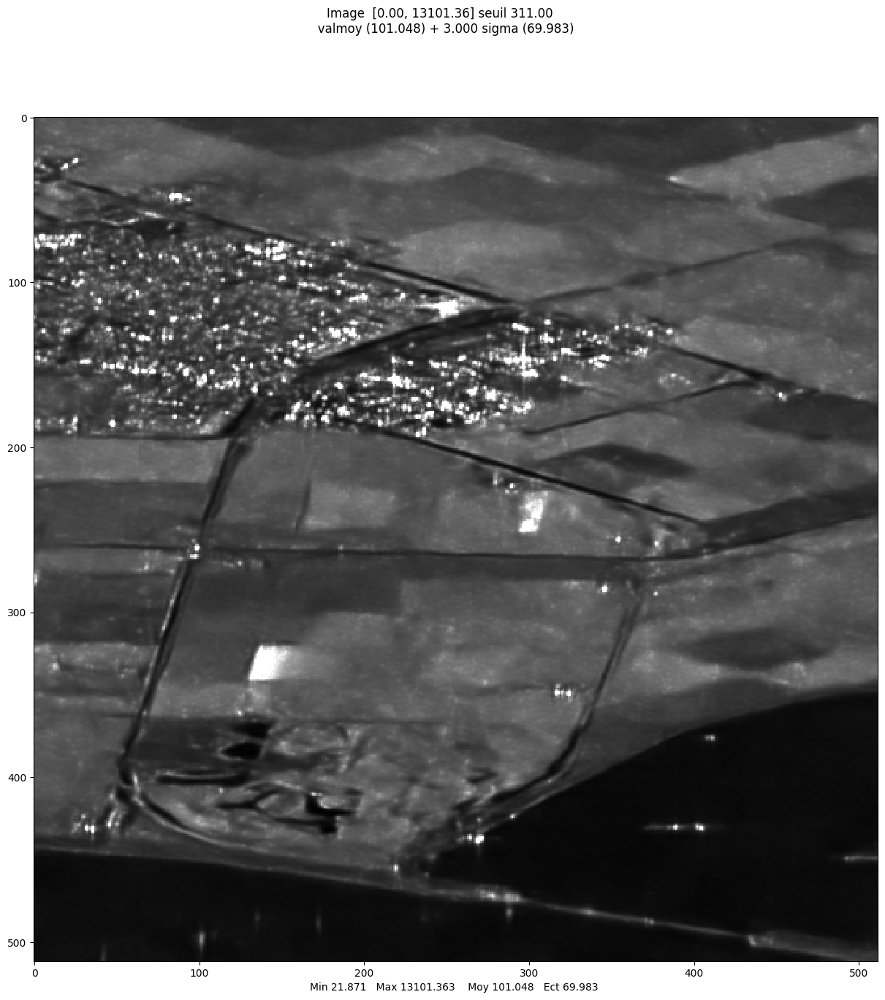

array([[108.26735687, 108.92593384, 117.21216583, ...,  87.13925171,
         89.79171753,  89.75721741],
       [105.54544067, 111.25749207, 116.15348053, ...,  95.23865509,
         96.19988251,  95.58480072],
       [105.72384644, 114.29315186, 116.50016022, ..., 100.59217072,
        100.78230286, 100.22771454],
       ...,
       [ 40.31035233,  38.88003159,  38.09856415, ...,  82.76222992,
         81.49038696,  81.83437347],
       [ 39.99552917,  38.5390358 ,  38.96235657, ...,  84.42482758,
         84.06273651,  83.64545441],
       [ 40.69298935,  38.59126282,  38.61891174, ...,  81.21070862,
         82.10493469,  87.46295166]])

In [ ]:
# this image has already been processed by a CNN based filter
!wget https://perso.telecom-paristech.fr/tupin/TPSAR/pilelely/denoised_SAR2SAR/lely_tuple_multitemp_SAR2SAR.IMA
!wget https://perso.telecom-paristech.fr/tupin/TPSAR/pilelely/denoised_SAR2SAR/lely_tuple_multitemp_SAR2SAR.dim
im_lely_multitemp_denoised = mvalab.imz2mat('lely_tuple_multitemp_SAR2SAR.IMA')
im1_d = np.abs(im_lely_multitemp_denoised[0][:,:,0]) #amplitude
mvalab.visusar(im1_d)

### Question C.4
Do a comparison between the CNN filtering and the Lee filter. Comment the two results. Are homogeneous areas well restored? Do the methods preserve edges and fine structures? Are artifacts introduced?



### Answer C.4
Both results are quite good however there are some issues. We can see in particular some artifacts have been introduced in the CNN, resulting in bright white spots, though they also exist in the lee filter, but much less pronounced. As for homogenous areas, both do it quite well, and the CNN preserves edges and fine structures much better as it doesn't have any blockiness.

## C.5 Method noise
Performances of a denoising algorithm can be visually interpreted by looking at the *residual noise* (i.e. the ratio between the noisy image and the denoised image, in intensity). For a quantitative evaluation, we can look at the noise statistics, knowing that, in intensity, statistics of speckle S are:
- $\mu_S=1$
- $\sigma^2_S = \frac{1}{L}$

### Question C.5
Compute the aforementioned ratio image, mean value and variance for the image restored using the Lee filter and the result of SAR2SAR. Comment the results.

What is the interest of computing the method noise ? What are your conclusions for the two previous filters ?

### Answer C.5

The mean and variance values are not surprising, indeed, most of the Lee filter is very dark with a few bright spots, which means low variance and mean, whereas the SAR2SAR has both more varaince in brightness overall (large dark areas next to large bright areas) and it is brighter overall.

Method noise is interesting to compute because it provides a quantitative measure of the effectiveness of a denoising algorithm. With this measure, we can see that SAR2SAR is a more effective algorithm as it has a higher mean and lower variance which is what we want from both filters.

Affichage d'une image reelle
plt.show dans visusar : image 512 x 512


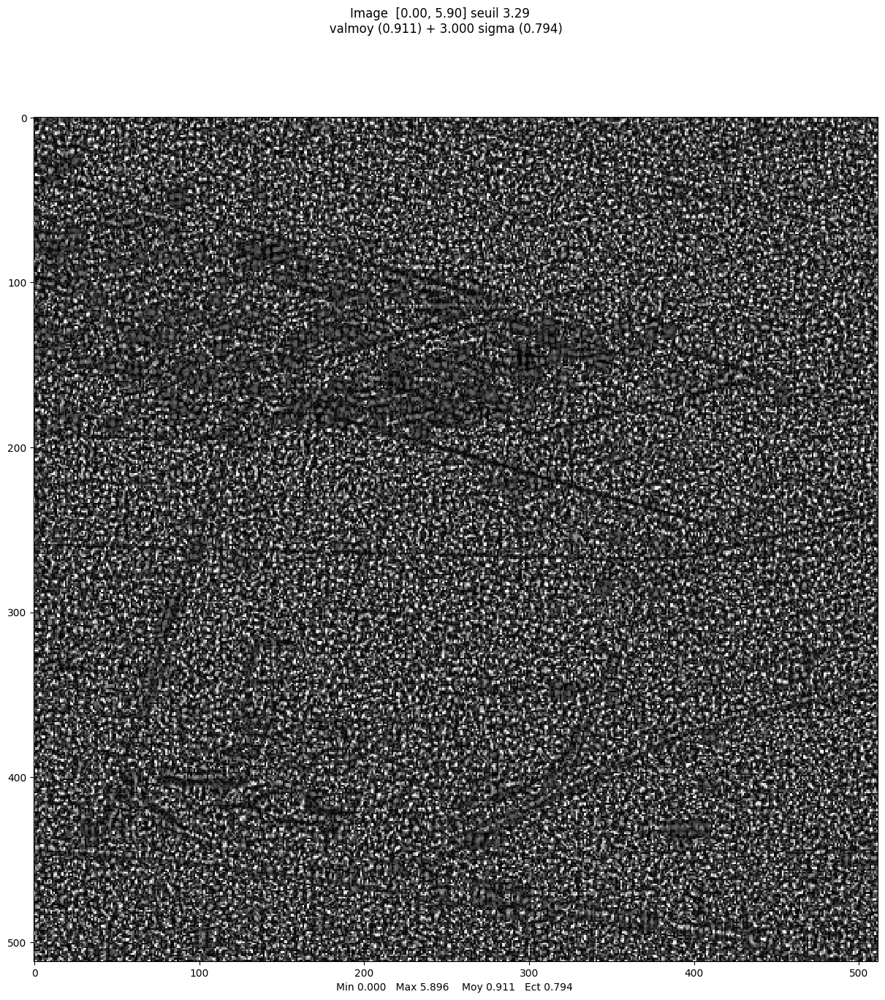

Affichage d'une image reelle
plt.show dans visusar : image 512 x 512


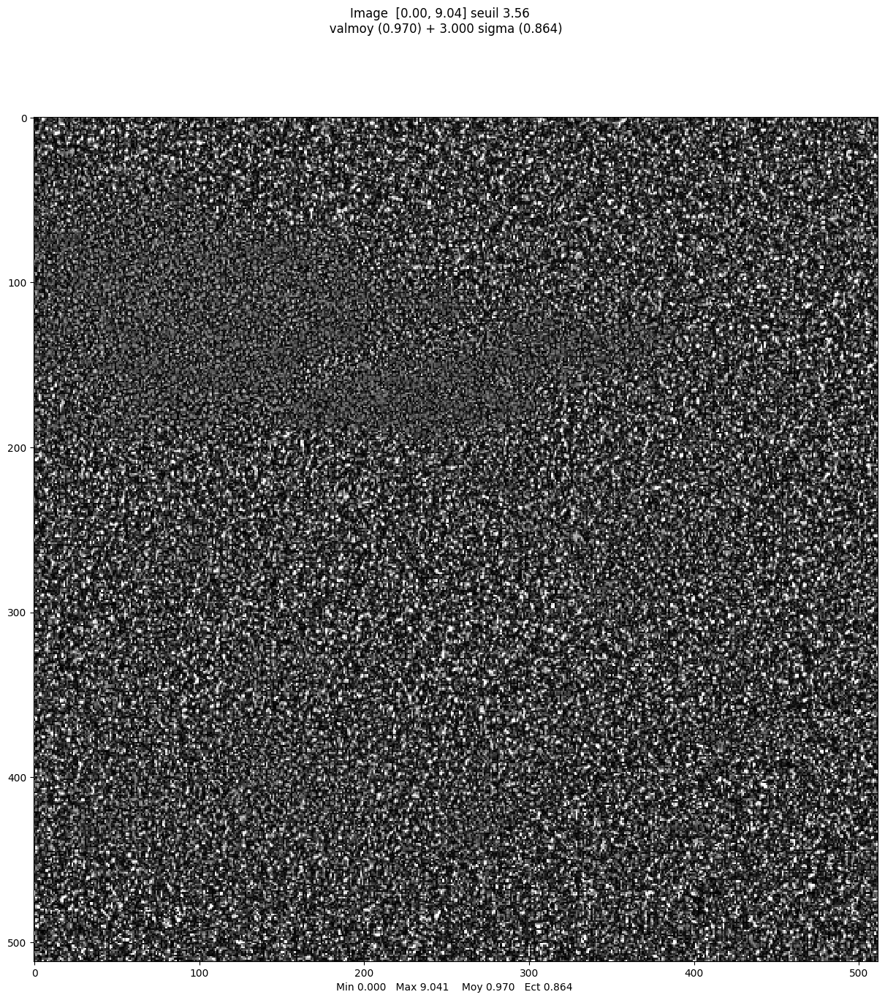

LEE FILTER: mean = 0.9109006966505614 and var = 0.6302988869868443
SAR2SAR: mean = 0.9697834638584217 and var = 0.7457658171745046


In [ ]:
# Plot the residual noise
res_noise_lee = part_lely_int / (lee_filtered_int) #complete
mvalab.visusar(res_noise_lee)
mean_lee = np.mean(res_noise_lee)
var_lee = np.var(res_noise_lee)

res_noise_deep = part_lely_int / (im1_d**2) #complete
mvalab.visusar(res_noise_deep)
mean_deep = np.mean(res_noise_deep)
var_deep = np.var(res_noise_deep)

print('LEE FILTER: mean = '+str(mean_lee)+' and var = '+str(var_lee))
print('SAR2SAR: mean = '+str(mean_deep)+' and var = '+str(var_deep))